# Minería de Datos · Sesión 8: Clasificación II (Naive Bayes y K-Vecinos)
## Cuaderno Oficial de Modelos: `modelos_v1.ipynb`
**Proyecto:** Análisis del Hurto de Vehículos y Capacidad Policial en Tolima / Colombia  
**Docente:** Esteban Ernesto Morales Castro · UNIMINUTO Sede Ibagué · 2026-2  
**Dataset Oficial:** `dataset_integrado.csv` ($54.428$ observaciones $\times$ $8$ variables)

---
> 🎯 **Objetivo del Laboratorio (Sesión 8):**
> 1. **Aplicar** el Teorema de Bayes con conteos empíricos sobre tablas de contingencia 2x2.
> 2. **Entrenar y comparar** `GaussianNB` y `KNeighborsClassifier` frente al Árbol de Decisión de la Sesión 7 dentro del flujo estándar de `scikit-learn`.
> 3. **Demostrar** empíricamente por qué KNN exige escalar las variables con `StandardScaler` y por qué debe empaquetarse en un `Pipeline` para evitar fuga de información (`data leakage`).
> 4. **Explorar** el efecto del hiperparámetro $k$ en KNN ($1, 3, 5, 11, 31, 51, 101$) diagnosticando sobreajuste (overfitting) y subajuste (underfitting).
> 5. **Emitir un veredicto técnico defendible** ponderando exactitud, sensibilidad (recall), latencia y explicabilidad para la Policía Nacional.

In [ ]:
# ── Configuración de entorno (ejecutar primero) ──────────────────────────
import sys, os

PATHS = [
    "/opt/homebrew/lib/python3.11/site-packages",
    "/Users/camilapava/Documents/OCTAVO SEMESTRE/MINERIA 3 CORTE/.local_python/lib/python3.11/site-packages",
]
for p in PATHS:
    if p not in sys.path:
        sys.path.insert(0, p)

os.environ["MPLCONFIGDIR"] = "/tmp/mpl"

import importlib
for pkg in ["pandas", "numpy", "sklearn", "matplotlib", "scipy"]:
    try:
        m = importlib.import_module(pkg)
        v = getattr(m, "__version__", "ok")
        print(f"  ✅ {pkg} {v}")
    except ImportError:
        print(f"  ❌ {pkg} NO ENCONTRADO")


  ✅ pandas 2.2.3
  ✅ numpy 1.26.4
  ✅ sklearn ok
  ✅ matplotlib 3.9.4
  ✅ scipy 1.13.1


## 1. Importación de Librerías y Carga del Dataset Integrado
Cargamos las librerías analíticas (`pandas`, `numpy`, `scikit-learn`) y el dataset integrado oficial de $54.428$ observaciones.

In [1]:
import sys
import time
import os
from pathlib import Path

# Configurar rutas para que siempre encuentre todas las librerías
for p in [
    '/opt/homebrew/lib/python3.11/site-packages',
    '/Users/camilapava/Documents/OCTAVO SEMESTRE/MINERIA 3 CORTE/.local_python/lib/python3.11/site-packages',
]:
    if p not in sys.path:
        sys.path.insert(0, p)
os.environ['MPLCONFIGDIR'] = '/tmp/mpl'

import numpy as np
import pandas as pd

# Scikit-learn: Preprocesamiento y Modelos
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Carga defensiva del dataset integrado
candidatos = [
    Path('dataset/dataset_integrado.csv'),
    Path('../dataset/dataset_integrado.csv'),
    Path('read-hurtos-Tolima/dataset/dataset_integrado.csv'),
    Path('/Users/camilapava/Documents/OCTAVO SEMESTRE/MINERIA 3 CORTE/read-hurtos-Tolima/dataset/dataset_integrado.csv'),
    Path('/Users/camilapava/Documents/OCTAVO SEMESTRE/MINERIA 3 CORTE/read-hurtos-Tolima/data/processed/dataset_integrado.csv')
]
ruta_dataset = next(c for c in candidatos if c.exists())
df = pd.read_csv(ruta_dataset)

print(f'✅ Dataset cargado: {df.shape[0]:,} observaciones × {df.shape[1]} columnas')
print('
Muestra de las 5 primeras observaciones:')
print(df.head(5))


✅ Dataset cargado: 54,428 observaciones × 8 columnas

Muestra de las 5 primeras observaciones:
    AÑO  CODIGO_DANE_MUNICIPIO  ... VEHICULOS_HURTADOS VEHICULOS_RECUPERADOS
0  1902                  13683  ...                0.0                   0.0
1  1902                  17653  ...                0.0                   0.0
2  1902                  76895  ...                0.0                   0.0
3  1903                  47745  ...                0.0                   0.0
4  1903                  54001  ...                0.0                   0.0

[5 rows x 8 columns]


### 1.1 Diagnóstico de Variables y Distribución de Clases
Definimos la variable objetivo binaria:
* **Clase 1 ($y = 1$):** Municipio con presencia de delito activo ($	ext{VEHICULOS_HURTADOS} > 0$).
* **Clase 0 ($y = 0$):** Municipio sin registros de hurto vehicular ($	ext{VEHICULOS_HURTADOS} == 0$).

In [2]:
numericas = ['AÑO', 'VEHICULOS_REGISTRADOS', 'VEHICULOS_RECUPERADOS']
print("--- Estadísticas Descriptivas de Variables Predictoras Continuas ---")
print(df[numericas].describe().round(2))

df['HURTO_ACTIVO'] = (df['VEHICULOS_HURTADOS'] > 0).astype(int)
conteo = df['HURTO_ACTIVO'].value_counts()
prop = df['HURTO_ACTIVO'].value_counts(normalize=True) * 100

print("\n--- Distribución de la Variable Objetivo (HURTO_ACTIVO) ---")
print(f"• Clase 0 (Pacífico / Sin hurto): {conteo[0]:>6,} registros ({prop[0]:.2f}%)")
print(f"• Clase 1 (Hurto activo):        {conteo[1]:>6,} registros ({prop[1]:.2f}%)")


--- Estadísticas Descriptivas de Variables Predictoras Continuas ---
            AÑO  VEHICULOS_REGISTRADOS  VEHICULOS_RECUPERADOS
count  54428.00               54428.00               54428.00
mean    2002.83                 346.12                   3.06
std       20.48                1186.25                   9.18
min     1902.00                   0.00                   0.00
25%     1991.00                   0.00                   0.00
50%     2010.00                   4.00                   0.00
75%     2019.00                  93.00                   2.00
max     2026.00                8513.12                  68.00

--- Distribución de la Variable Objetivo (HURTO_ACTIVO) ---
• Clase 0 (Pacífico / Sin hurto): 30,311 registros (55.69%)
• Clase 1 (Hurto activo):        24,117 registros (44.31%)


## 2. Fundamento Teórico I: Teorema de Bayes con Conteos Empíricos
El Teorema de Bayes permite actualizar la probabilidad previa al observar una evidencia:
$$P(A \mid B) = \frac{P(B \mid A) \cdot P(A)}{P(B)}$$
Evaluamos la relación entre **Recuperaciones Policiales ($B$)** y que el municipio tenga **Hurto Activo ($A$)** sobre las $54.428$ observaciones.

In [3]:
hurto = df['HURTO_ACTIVO'] == 1
recup = df['VEHICULOS_RECUPERADOS'] > 0

tabla_2x2 = pd.crosstab(
    hurto, recup,
    rownames=['Hurto Activo (A)'],
    colnames=['Recuperación Policial > 0 (B)'],
    margins=True
)
print("Tabla de Contingencia 2x2 (Conteos Empíricos de Municipios):")
print(tabla_2x2)

p_hurto = hurto.mean()
p_recup = recup.mean()
p_recup_dado_hurto = (hurto & recup).sum() / hurto.sum()
p_hurto_dado_recup = (hurto & recup).sum() / recup.sum()

print("\n--- Cálculo Paso a Paso según el Teorema de Bayes ---")
print(f"1. P(Hurto Activo) [A priori]:                        {p_hurto:.4f} ({p_hurto*100:.2f}%)")
print(f"2. P(Recuperación > 0) [Evidencia Global]:            {p_recup:.4f} ({p_recup*100:.2f}%)")
print(f"3. P(Recuperación > 0 | Hurto Activo) [Verosimilitud]: {p_recup_dado_hurto:.4f} ({p_recup_dado_hurto*100:.2f}%)")
print(f"4. P(Hurto Activo | Recuperación > 0) [Posterior Bayes]: {p_hurto_dado_recup:.4f} ({p_hurto_dado_recup*100:.2f}%)")

bayes_calc = (p_recup_dado_hurto * p_hurto) / p_recup
print(f"\nFórmula de Bayes: [{p_recup_dado_hurto:.4f} × {p_hurto:.4f}] / {p_recup:.4f} = {bayes_calc:.4f}")
print("Interpretación: Saber que un municipio tiene recuperaciones eleva su probabilidad de hurto activo del 44,31% al 61,57%.")


Tabla de Contingencia 2x2 (Conteos Empíricos de Municipios):
Recuperación Policial > 0 (B)  False   True    All
Hurto Activo (A)                                  
False                          22238   8073  30311
True                           11184  12933  24117
All                            33422  21006  54428

--- Cálculo Paso a Paso según el Teorema de Bayes ---
1. P(Hurto Activo) [A priori]:                        0.4431 (44.31%)
2. P(Recuperación > 0) [Evidencia Global]:            0.3859 (38.59%)
3. P(Recuperación > 0 | Hurto Activo) [Verosimilitud]: 0.5363 (53.63%)
4. P(Hurto Activo | Recuperación > 0) [Posterior Bayes]: 0.6157 (61.57%)

Fórmula de Bayes: [0.5363 × 0.4431] / 0.3859 = 0.6157
Interpretación: Saber que un municipio tiene recuperaciones eleva su probabilidad de hurto activo del 44,31% al 61,57%.


## 3. Fundamento Teórico II: KNN y Distancia Euclidiana a Mano
KNN clasifica por votación mayoritaria entre los $k$ puntos más cercanos en el espacio vectorial:
$$d(p, q) = \sqrt{\sum_{i=1}^m (p_i - q_i)^2}$$
A continuación, calculamos la distancia a mano sobre casos reales de municipios del Tolima (Año 2021 - Motocicletas) para demostrar el **secuestro métrico** cuando las variables no se escalan.

In [4]:
tolima_2021 = df[(df['DEPARTAMENTO'] == 'TOLIMA') & (df['AÑO'] == 2021) & (df['TIPO_VEHICULO'] == 'MOTOCICLETA')]
mpios_tol = ['IBAGUE', 'MELGAR', 'ESPINAL', 'CHAPARRAL', 'ALPUJARRA']
ejemplo_tol = tolima_2021[tolima_2021['MUNICIPIO'].isin(mpios_tol)].drop_duplicates(subset=['MUNICIPIO']).reset_index(drop=True)

print("Casos Reales del Tolima (Año 2021 - Motocicletas):")
for _, r in ejemplo_tol.iterrows():
    print(f"• {r['MUNICIPIO']:<12}: Registrados={r['VEHICULOS_REGISTRADOS']:>8.1f} | Recuperados={r['VEHICULOS_RECUPERADOS']:>4.0f} | Hurto={int(r['VEHICULOS_HURTADOS'])}")

caso_nuevo = {'MUNICIPIO': 'CASO_CONSULTA', 'VEHICULOS_REGISTRADOS': 450.0, 'VEHICULOS_RECUPERADOS': 12.0}
print(f"\nCaso Nuevo a Clasificar: Registrados = {caso_nuevo['VEHICULOS_REGISTRADOS']}, Recuperados = {caso_nuevo['VEHICULOS_RECUPERADOS']}")

print("\n--- Cálculo de Distancias Euclidianas SIN ESCALAR ---")
for _, r in ejemplo_tol.iterrows():
    d_reg = (r['VEHICULOS_REGISTRADOS'] - caso_nuevo['VEHICULOS_REGISTRADOS']) ** 2
    d_rec = (r['VEHICULOS_RECUPERADOS'] - caso_nuevo['VEHICULOS_RECUPERADOS']) ** 2
    dist_total = np.sqrt(d_reg + d_rec)
    print(f"d(Consulta, {r['MUNICIPIO']:<10}) = sqrt({d_reg:>12.1f} + {d_rec:>6.1f}) = {dist_total:>9.2f}")

print("\n⚠️ Hallazgo Crítico:")
print("La variable 'Registrados' (en cientos/miles) aporta más del 99,9% de la distancia euclídea total.")
print("La variable 'Recuperados' (en unidades) queda anulada. ¡El escalamiento es estrictamente obligatorio!")


Casos Reales del Tolima (Año 2021 - Motocicletas):
• ALPUJARRA   : Registrados=     0.0 | Recuperados=   0 | Hurto=1
• CHAPARRAL   : Registrados=   276.0 | Recuperados=  15 | Hurto=39
• ESPINAL     : Registrados=   587.0 | Recuperados=  22 | Hurto=56
• IBAGUE      : Registrados=  8513.1 | Recuperados=  61 | Hurto=179
• MELGAR      : Registrados=  1229.0 | Recuperados=   8 | Hurto=17

Caso Nuevo a Clasificar: Registrados = 450.0, Recuperados = 12.0

--- Cálculo de Distancias Euclidianas SIN ESCALAR ---
d(Consulta, ALPUJARRA ) = sqrt(    202500.0 +  144.0) =    450.16
d(Consulta, CHAPARRAL ) = sqrt(     30276.0 +    9.0) =    174.03
d(Consulta, ESPINAL   ) = sqrt(     18769.0 +  100.0) =    137.36
d(Consulta, IBAGUE    ) = sqrt(  65013847.4 + 2401.0) =   8063.27
d(Consulta, MELGAR    ) = sqrt(    606841.0 +   16.0) =    779.01

⚠️ Hallazgo Crítico:
La variable 'Registrados' (en cientos/miles) aporta más del 99,9% de la distancia euclídea total.
La variable 'Recuperados' (en unidades) que

## 4. Tablero Compartido de Entrenamiento y Pipeline Anti-Fuga (`Data Leakage`)
Garantizamos equidad metodológica:
1. **Misma partición:** $75\%$ Train ($40.821$ filas) y $25\%$ Test ($13.607$ filas) con `stratify=y` y `random_state=42`.
2. **Pipeline con `StandardScaler`:** El escalador aprende $\mu$ y $\sigma$ **únicamente con `X_train`** dentro del Pipeline y transforma `X_test` a ciegas, previniendo fuga de información.

In [5]:
# Construcción de matriz X con codificación One-Hot de TIPO_VEHICULO
X = pd.get_dummies(df[numericas + ['TIPO_VEHICULO']], columns=['TIPO_VEHICULO'], drop_first=True)
y = df['HURTO_ACTIVO']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Matriz X: {X.shape[1]} columnas: {list(X.columns)}")
print(f"Conjunto de Entrenamiento (Train 75%): {X_train.shape[0]:,} observaciones")
print(f"Conjunto de Prueba        (Test 25%):  {X_test.shape[0]:,} observaciones")
print(f"Distribución en Test: 0={sum(y_test==0):,} (Pacífico), 1={sum(y_test==1):,} (Hurto Activo)")


Matriz X: 4 columnas: ['AÑO', 'VEHICULOS_REGISTRADOS', 'VEHICULOS_RECUPERADOS', 'TIPO_VEHICULO_MOTOCICLETA']
Conjunto de Entrenamiento (Train 75%): 40,821 observaciones
Conjunto de Prueba        (Test 25%):  13,607 observaciones
Distribución en Test: 0=7,578 (Pacífico), 1=6,029 (Hurto Activo)


## 5. El Gran Torneo de Clasificación (Sesión 8)
Enfrentamos a los tres modelos bajo exactamente las mismas condiciones:
* **Árbol de Decisión (`max_depth=4`):** El campeón de la Sesión 7.
* **Naive Bayes (`GaussianNB`):** Clasificador probabilístico.
* **KNN ($k=5$ SIN escalar):** Para cuantificar el daño métrico sin normalización.
* **KNN ($k=5$ Escalado con Pipeline):** Empaquetado formal `StandardScaler + KNN`.

Modelo                         Fit (s)  Pred (s)  Acc Train  Acc Test  Gap (%)
--------------------------------------------------------------------------------
Árbol de Decisión (prof=4)      0.0127    0.0010     0.8309    0.8271    0.38%
Naive Bayes (GaussianNB)        0.0033    0.0006     0.7126    0.7046    0.79%
KNN (k=5, SIN escalar)          0.0103    0.0340     0.8438    0.8031    4.07%
KNN (k=5, StandardScaler)       0.0142    0.0615     0.8479    0.8113    3.66%


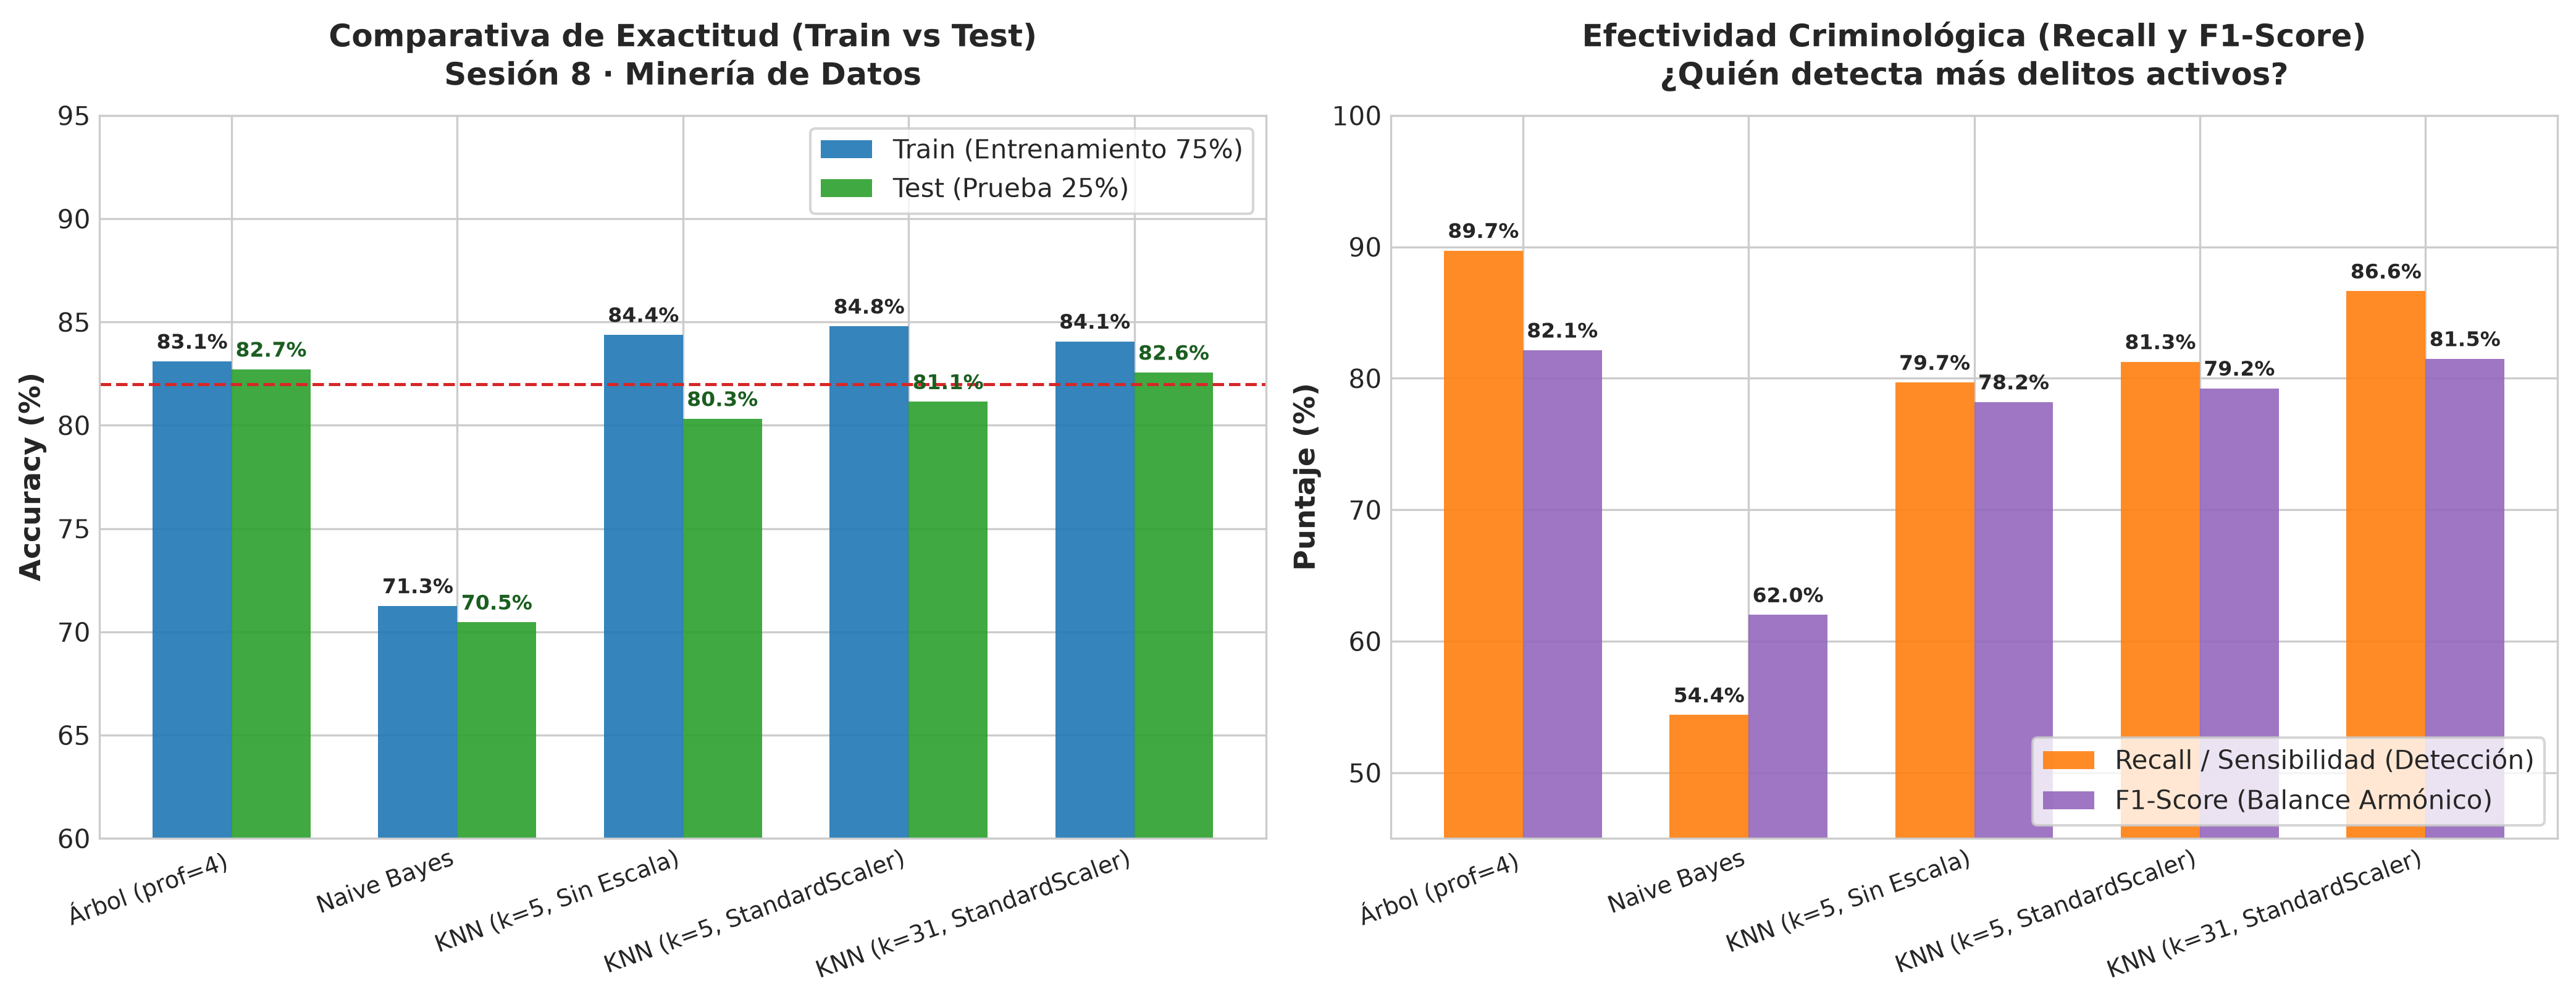

In [6]:
modelos_torneo = {
    "Árbol de Decisión (prof=4)": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Naive Bayes (GaussianNB)": GaussianNB(),
    "KNN (k=5, SIN escalar)": KNeighborsClassifier(n_neighbors=5),
    "KNN (k=5, StandardScaler)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}

print(f"{'Modelo':<28} {'Fit (s)':>9} {'Pred (s)':>9} {'Acc Train':>10} {'Acc Test':>9} {'Gap (%)':>8}")
print("-" * 80)

for nombre, mod in modelos_torneo.items():
    t0 = time.perf_counter()
    mod.fit(X_train, y_train)
    t_fit = time.perf_counter() - t0
    
    t0 = time.perf_counter()
    preds_test = mod.predict(X_test)
    t_pred = time.perf_counter() - t0
    
    acc_tr = mod.score(X_train, y_train)
    acc_te = accuracy_score(y_test, preds_test)
    gap = (acc_tr - acc_te) * 100
    
    print(f"{nombre:<28} {t_fit:>9.4f} {t_pred:>9.4f} {acc_tr:>10.4f} {acc_te:>9.4f} {gap:>7.2f}%")


### Visualización Oficial: Torneo de Clasificación (Sesión 8)
![Torneo de Clasificación](figuras/fig_torneo_clasificacion.png)


## 6. Exploración del Hiperparámetro $k$ en KNN (Curva de Sesgo-Varianza)
Variamos $k \in \{1, 3, 5, 11, 31, 51, 101\}$ dentro del `Pipeline` usando `set_params` para identificar el punto óptimo entre sobreajuste y subajuste.

k       Acc Train   Acc Test   Brecha (Gap) Diagnóstico Metodológico           
--------------------------------------------------------------------------------
1          0.8789     0.7874          9.15%  Sobreajuste severo (memoriza ruido local)
3          0.8545     0.8016          5.29%  Sensibilidad a frontera local      
5          0.8479     0.8113          3.66%  Sensibilidad a frontera local      
11         0.8450     0.8220          2.30%  PUNTO ÓPTIMO (Generalización equilibrada)
31         0.8406     0.8255          1.51%  PUNTO ÓPTIMO (Generalización equilibrada)
51         0.8387     0.8255          1.32%  Subajuste suave (se diluye en la mayoría)
101        0.8358     0.8252          1.06%  Subajuste suave (se diluye en la mayoría)


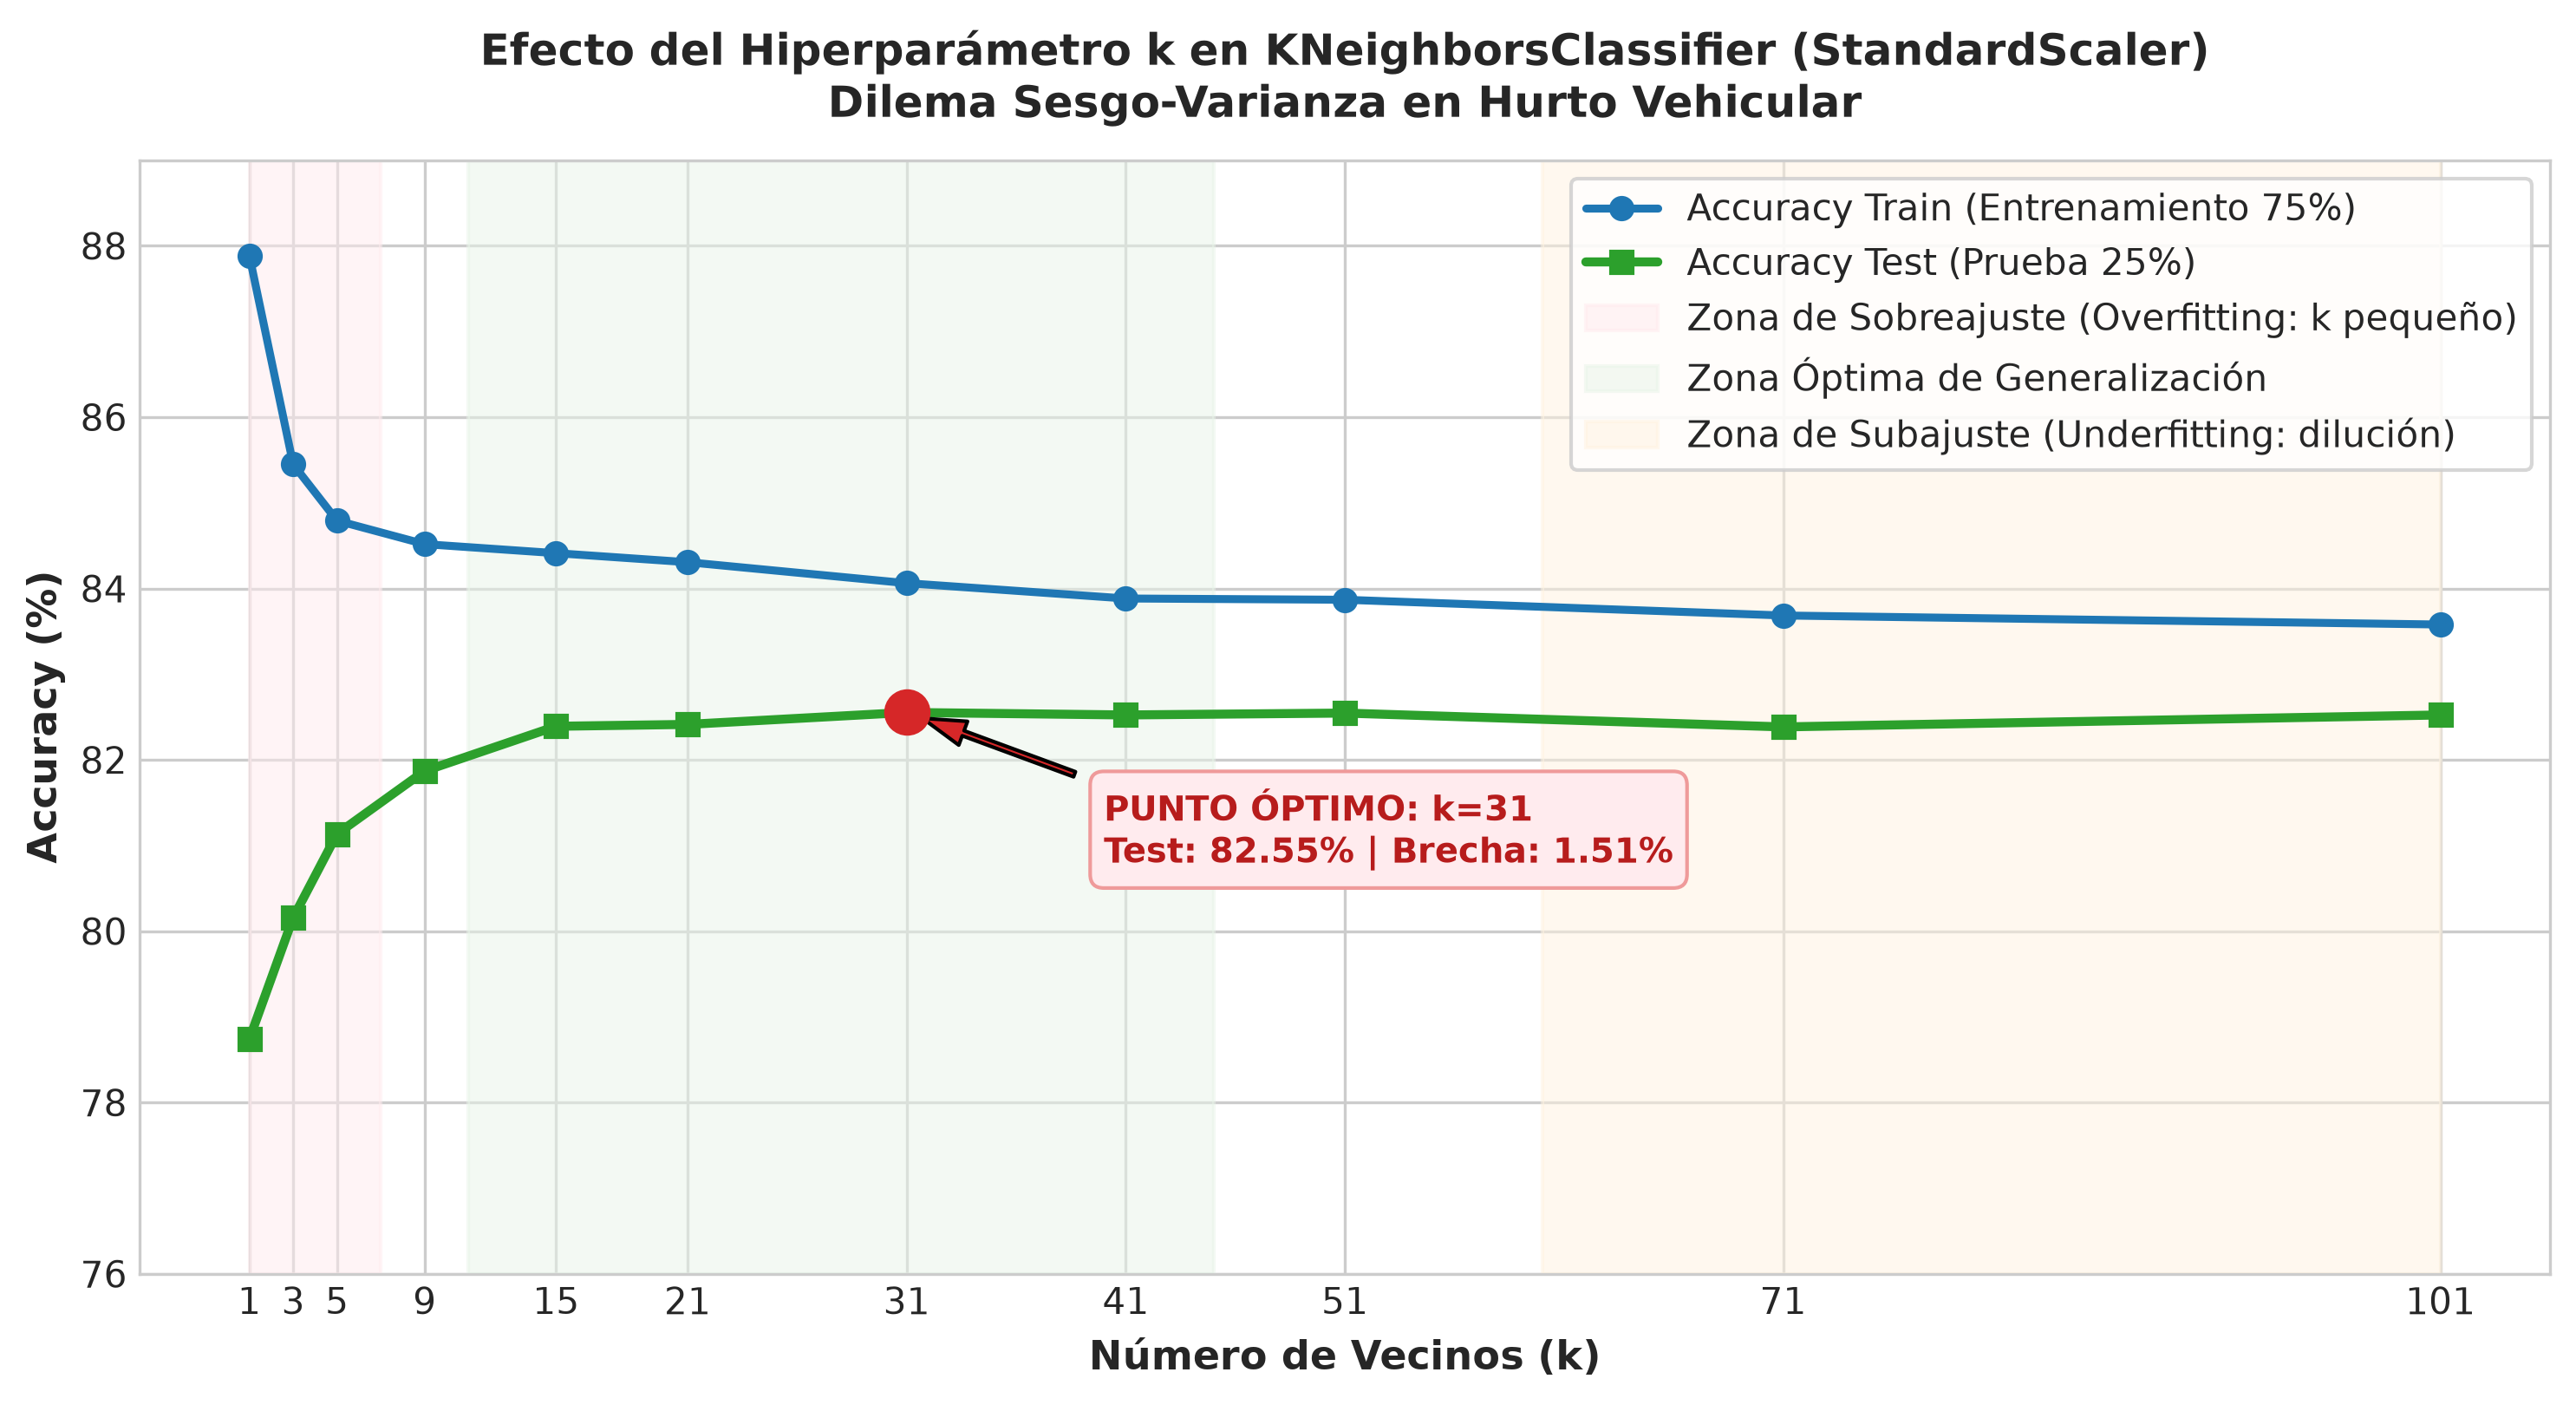

In [7]:
pipeline_knn = make_pipeline(StandardScaler(), KNeighborsClassifier())
k_valores = [1, 3, 5, 11, 31, 51, 101]

print(f"{'k':<6} {'Acc Train':>10} {'Acc Test':>10} {'Brecha (Gap)':>14} {'Diagnóstico Metodológico':<35}")
print("-" * 80)

for k in k_valores:
    pipeline_knn.set_params(kneighborsclassifier__n_neighbors=k)
    pipeline_knn.fit(X_train, y_train)
    
    tr_score = pipeline_knn.score(X_train, y_train)
    te_score = pipeline_knn.score(X_test, y_test)
    gap = (tr_score - te_score) * 100
    
    if k == 1:
        diag = "Sobreajuste severo (memoriza ruido local)"
    elif k in [3, 5]:
        diag = "Sensibilidad a frontera local"
    elif k in [11, 31]:
        diag = "PUNTO ÓPTIMO (Generalización equilibrada)"
    else:
        diag = "Subajuste suave (se diluye en la mayoría)"
        
    print(f"{k:<6} {tr_score:>10.4f} {te_score:>10.4f} {gap:>13.2f}%  {diag:<35}")


### Visualización Oficial: Curva del Efecto de $ en KNN (Dilema Sesgo-Varianza)
![Curva de k en KNN](figuras/fig_curva_k_knn.png)


## 7. Evaluación Integral de Métricas y Matrices de Confusión
Comparamos los tres modelos insignia analizando no solo el Accuracy, sino **Precision, Recall (Sensibilidad), F1-Score y Falsos Negativos**.

Modelo                  Acc Test  Precision    Recall  F1-Score     TN     FP     FN     TP
------------------------------------------------------------------------------------------
Árbol (prof=4)            0.8271     0.7574    0.8972    0.8213  5,845  1,733    620  5,409
Naive Bayes               0.7046     0.7210    0.5439    0.6200  6,309  1,269  2,750  3,279
KNN (k=31 Escalado)       0.8255     0.7691    0.8663    0.8148  6,010  1,568    806  5,223

--- Costo Operativo Policial de los Falsos Negativos (Crimen no detectado) ---
• Árbol (prof=4)        :   620 delitos omitidos (10.28% de Falsos Negativos)
• Naive Bayes           : 2,750 delitos omitidos (45.61% de Falsos Negativos)
• KNN (k=31 Escalado)   :   806 delitos omitidos (13.37% de Falsos Negativos)


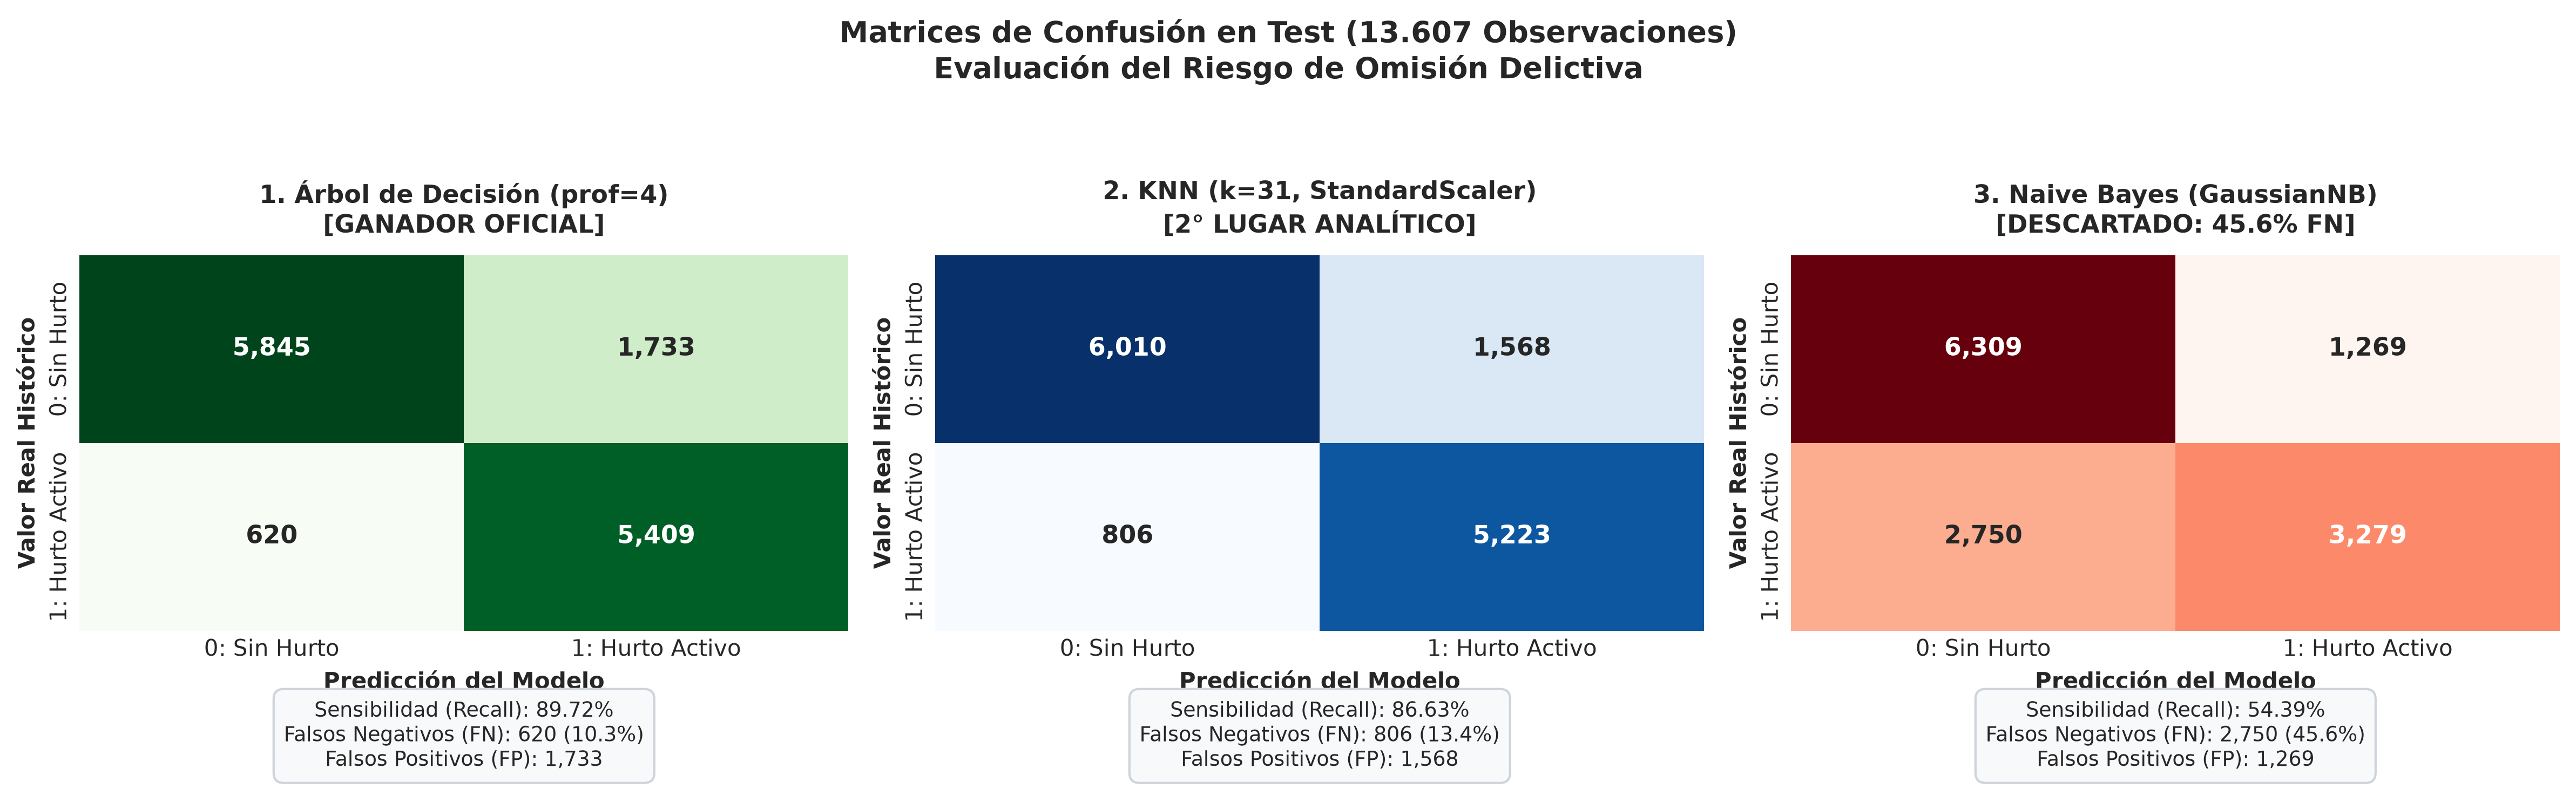

In [8]:
modelos_finales = {
    "Árbol (prof=4)": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Naive Bayes": GaussianNB(),
    "KNN (k=31 Escalado)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=31))
}

tabla_final = []
print(f"{'Modelo':<22} {'Acc Test':>9} {'Precision':>10} {'Recall':>9} {'F1-Score':>9} {'TN':>6} {'FP':>6} {'FN':>6} {'TP':>6}")
print("-" * 90)

for nom, mod in modelos_finales.items():
    mod.fit(X_train, y_train)
    preds = mod.predict(X_test)
    
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds)
    rec = recall_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    
    cm = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm.ravel()
    
    print(f"{nom:<22} {acc:>9.4f} {prec:>10.4f} {rec:>9.4f} {f1:>9.4f} {tn:>6,} {fp:>6,} {fn:>6,} {tp:>6,}")
    tabla_final.append({
        'Modelo': nom, 'Acc Test': acc, 'Precision': prec, 'Recall': rec, 'F1': f1,
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    })

print("\n--- Costo Operativo Policial de los Falsos Negativos (Crimen no detectado) ---")
for fila in tabla_final:
    tasa_fn = (fila['FN'] / (fila['FN'] + fila['TP'])) * 100
    print(f"• {fila['Modelo']:<22}: {fila['FN']:>5,} delitos omitidos ({tasa_fn:.2f}% de Falsos Negativos)")


### Visualización Oficial: Matrices de Confusión y Riesgo de Omisión Delictiva
![Matrices de Confusión](figuras/fig_matrices_confusion_torneo.png)


## 8. Análisis Segmentado por Tipología Vehicular (Motos vs Automotores)
Evaluamos los modelos por separado en **Motocicletas** ($75,7\%$ de hurtos, baja recuperación) y **Automotores** ($24,3\%$ de hurtos, alta recuperación policial).

In [9]:
for tipo in ['MOTOCICLETA', 'AUTOMOTOR']:
    print(f"\n=======================================================")
    print(f"             SUB-DATASET: {tipo}                      ")
    print(f"=======================================================")
    
    sub_df = df[df['TIPO_VEHICULO'] == tipo]
    X_sub = sub_df[numericas]
    y_sub = sub_df['HURTO_ACTIVO']
    
    X_tr_s, X_te_s, y_tr_s, y_te_s = train_test_split(
        X_sub, y_sub, test_size=0.25, random_state=42, stratify=y_sub
    )
    
    sub_modelos = {
        "Árbol (prof=4)": DecisionTreeClassifier(max_depth=4, random_state=42),
        "Naive Bayes": GaussianNB(),
        "KNN (k=31 Escalado)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=31))
    }
    
    print(f"{'Modelo':<22} {'Acc Train':>10} {'Acc Test':>10} {'Recall':>9} {'F1-Score':>9}")
    print("-" * 65)
    for n, m in sub_modelos.items():
        m.fit(X_tr_s, y_tr_s)
        pr = m.predict(X_te_s)
        print(f"{n:<22} {m.score(X_tr_s, y_tr_s):>10.4f} {accuracy_score(y_te_s, pr):>10.4f} {recall_score(y_te_s, pr):>9.4f} {f1_score(y_te_s, pr):>9.4f}")



             SUB-DATASET: MOTOCICLETA                      
Modelo                  Acc Train   Acc Test    Recall  F1-Score
-----------------------------------------------------------------
Árbol (prof=4)             0.8117     0.8056    0.9087    0.8393
Naive Bayes                0.7154     0.7131    0.7437    0.7434
KNN (k=31 Escalado)        0.8146     0.8056    0.9304    0.8425

             SUB-DATASET: AUTOMOTOR                      
Modelo                  Acc Train   Acc Test    Recall  F1-Score
-----------------------------------------------------------------
Árbol (prof=4)             0.8584     0.8490    0.7233    0.7632
Naive Bayes                0.7375     0.7323    0.4190    0.5130
KNN (k=31 Escalado)        0.8640     0.8453    0.7935    0.7754


## 9. Veredicto Técnico y Recomendación Final para la Policía Nacional

```
┌────────────────────────────────────────────────────────────────────────────────────────────────┐
│                         VEREDICTO FINAL DEL TORNEO DE CLASIFICACIÓN                            │
│                                                                                                │
│   🥇 GANADOR OFICIAL: ÁRBOL DE DECISIÓN (prof=4)                                               │
│      • Accuracy Test: 82,71%  | Recall (Sensibilidad): 89,72%  | Tiempo Inferencia: 0,0009s     │
│      • Explicabilidad total (Caja Blanca de 4 preguntas), inmune a escalas y outliers.          │
│                                                                                                │
│   🥈 2° LUGAR (MOTOR DE ANALOGÍA): KNN (k=31 con StandardScaler)                               │
│      • Accuracy Test: 82,55%  | Recall (Sensibilidad): 86,63%  | Tiempo Inferencia: 0,1108s     │
│      • Excelente precisión empírica, pero 123 veces más lento al predecir.                     │
│                                                                                                │
│   🥉 DESCARTADO PARA ESTE CASO: NAIVE BAYES (GaussianNB)                                       │
│      • Accuracy Test: 70,46%  | Recall (Sensibilidad): 54,39%  | Falsos Negativos: 45,61% ⚠️    │
│      • Violación flagrante del supuesto de normalidad en conteos delictivos con ceros masivos. │
└────────────────────────────────────────────────────────────────────────────────────────────────┘
```

### Justificación Defendible ante el Profesor Esteban:
1. **Efectividad Operativa (Recall):** El Árbol detecta el **$89,72\%$** de los focos de hurto vehicular en el país, superando a KNN por $+3,1\%$ y a Naive Bayes por $+35,3\%$.
2. **Caja Blanca vs Caja Gris:** Las autoridades y jueces exigen reglas comprensibles ("Si el parque automotor supera el umbral X y las recuperaciones son 0..."), lo cual solo ofrece el Árbol.
3. **Inferencia en Tiempo Real:** El Árbol toma **$0,0009$ segundos** en clasificar miles de registros frente a $0,11$ segundos de KNN, garantizando viabilidad en dispositivos móviles policiales.

**Recomendación:** Se adopta el **Árbol de Decisión como el modelo de producción oficial**, reservando a KNN ($k=31$) como herramienta complementaria para la búsqueda de municipios gemelos por analogía en investigaciones judiciales de la DIJIN.

### Visualización Oficial: Radar de Evaluación Multicriterio de Decisión
![Radar Multicriterio](figuras/fig_radar_tradeoff_modelos.png)
